# Lista de Exercícios: Aprendizado Supervisionado

Esta lista contém exercícios práticos para consolidação dos conceitos de **K-Nearest Neighbors (KNN)**, **Árvores de Decisão** e **Naive Bayes**.

Preencha o código onde estiver indicado por `# SEU CÓDIGO AQUI` e execute as células para validar os resultados.

## Exercício 1: Classificação com K-Nearest Neighbors (KNN)

**Dataset:** Iris  
**Objetivo:** Construir um modelo KNN para classificar a espécie da flor com base em suas características (`sepal_length`, `sepal_width`, `petal_length`, `petal_width`).

### Instruções:
1. Carregue o dataset Iris.
2. Separe os dados em features ($X$) e a variável alvo ($y$).
3. Divida os dados em conjuntos de treino e teste.
4. Treine um modelo `KNeighborsClassifier` (comece com `n_neighbors=5`).
5. Faça previsões no conjunto de teste.
6. Calcule a acurácia do modelo para avaliar seu desempenho.

In [20]:
# Importação das bibliotecas necessárias
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import pandas as pd

# 1. Carregar o dataset Iris
colunas_iris = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'class']
df = pd.read_csv('iris.data', header=None, names=colunas_iris)
print(df.head())
print('--------------')

# 2. Separar os dados em features (X) e variável alvo (y)
X = df.drop('class', axis=1)
y = df['class']
print(X.head())
print('--------------')
print(y.head())
print('--------------')

# 3. Dividir os dados em treino e teste (ex: 80% treino, 20% teste)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Treinar o modelo KNeighborsClassifier (n_neighbors=5)
model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, y_train)

# 5. Fazer previsões no conjunto de teste
y_pred = model.predict(X_test)

# 6. Calcular e exibir a acurácia
accuracy = accuracy_score(y_test, y_pred)
print(f"Model's Accuracy: {accuracy}")
print('--------------')

   sepal_length  sepal_width  petal_length  petal_width        class
0           5.1          3.5           1.4          0.2  Iris-setosa
1           4.9          3.0           1.4          0.2  Iris-setosa
2           4.7          3.2           1.3          0.2  Iris-setosa
3           4.6          3.1           1.5          0.2  Iris-setosa
4           5.0          3.6           1.4          0.2  Iris-setosa
--------------
   sepal_length  sepal_width  petal_length  petal_width
0           5.1          3.5           1.4          0.2
1           4.9          3.0           1.4          0.2
2           4.7          3.2           1.3          0.2
3           4.6          3.1           1.5          0.2
4           5.0          3.6           1.4          0.2
--------------
0    Iris-setosa
1    Iris-setosa
2    Iris-setosa
3    Iris-setosa
4    Iris-setosa
Name: class, dtype: object
--------------
Model's Accuracy: 1.0
--------------


---

## Exercício 2: Classificação com Árvore de Decisão

**Dataset:** Iris  
**Objetivo:** Desenvolver uma Árvore de Decisão para classificar a espécie da flor, focando na visualização do processo de tomada de decisão.

### Instruções:
1. Carregue o dataset Iris.
2. Separe os dados em features ($X$) e a variável alvo ($y$).
3. Treine um modelo `DecisionTreeClassifier`.
4. Visualize a árvore de decisão usando a função **`plot_tree`** da biblioteca `sklearn.tree` e `matplotlib.pyplot`.
5. Faça previsões com o modelo e calcule sua acurácia.

   sepal_length  sepal_width  petal_length  petal_width        class
0           5.1          3.5           1.4          0.2  Iris-setosa
1           4.9          3.0           1.4          0.2  Iris-setosa
2           4.7          3.2           1.3          0.2  Iris-setosa
3           4.6          3.1           1.5          0.2  Iris-setosa
4           5.0          3.6           1.4          0.2  Iris-setosa
--------------
Modelo treinado!


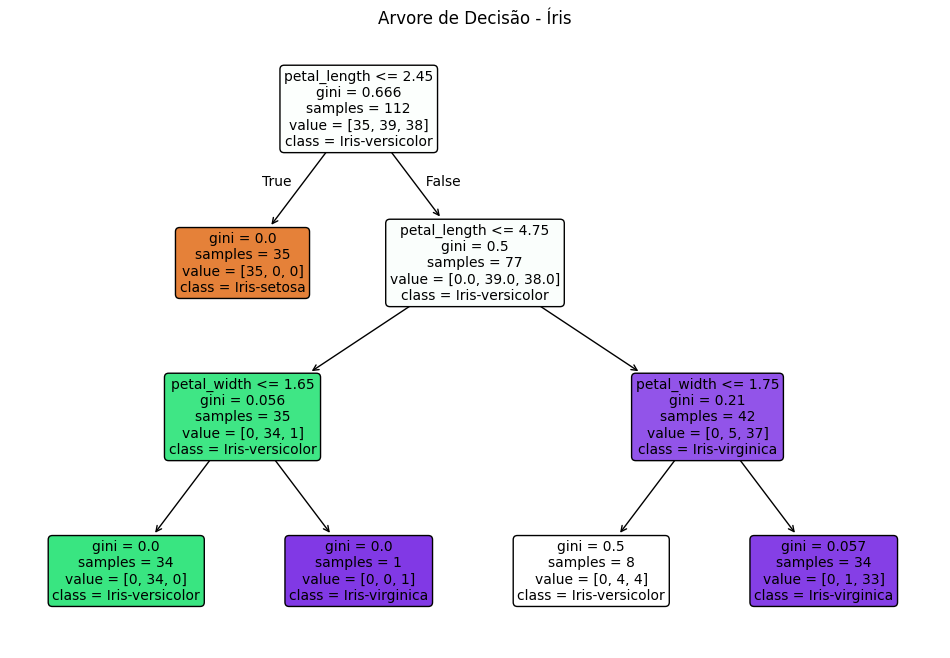

Acurácia do modelo: 100.00%


In [29]:
# Importação das bibliotecas necessárias
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# 1. Carregar o dataset Iris
colunas_iris = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'class']
df = pd.read_csv('iris.data', header=None, names=colunas_iris)
print(df.head())
print('--------------')

# 2. Separar em features (X) e alvo (y)
X = df.drop('class', axis=1)
y = df['class']

# Dividir dados em treino e teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# 3. Treinar o modelo DecisionTreeClassifier
model = DecisionTreeClassifier(max_depth=3, random_state=42)
model.fit(X_train, y_train)
print('Modelo treinado!')

# 4. Visualizar a árvore de decisão usando plot_tree
plt.figure(figsize=(12, 8))
plot_tree(model,
          feature_names=X_train.columns,
          class_names=model.classes_,
          filled=True,
          rounded=True,
          fontsize=10)
plt.title('Arvore de Decisão - Íris')
plt.show()

# 5. Fazer previsões e calcular a acurácia

# Acurácia:
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Acurácia do modelo: {accuracy:.2%}")


In [30]:
# Previsões:
def previsao_iris(dados):
    # Converte o dicionário com as medições em um DataFrame
    df_teste = pd.DataFrame([dados])

    # Garante que as colunas fiquem na mesma ordem do treinamento
    df_teste = df_teste[X_train.columns]

    # Realiza a predição da espécie
    resultado = model.predict(df_teste)

    print(f"\nMedições fornecidas: {dados}")
    print(f"Previsão da espécie: --> {resultado[0]}")


# Coleta dos dados via input (convertendo para float)
prev = {}
prev['sepal_length'] = float(input("Comprimento da sépala (cm): "))
prev['sepal_width'] = float(input("Largura da sépala (cm): "))
prev['petal_length'] = float(input("Comprimento da pétala (cm): "))
prev['petal_width'] = float(input("Largura da pétala (cm): "))

previsao_iris(prev)

Comprimento da sépala (cm): 5.2
Largura da sépala (cm): 3.4
Comprimento da pétala (cm): 1.1
Largura da pétala (cm): 2.3

Medições fornecidas: {'sepal_length': 5.2, 'sepal_width': 3.4, 'petal_length': 1.1, 'petal_width': 2.3}
Previsão da espécie: --> Iris-setosa


---

## Exercício 3: Classificação com Naive Bayes

**Dataset:** Titanic  
**Objetivo:** Utilizar o algoritmo Naive Bayes para prever a sobrevivência de um passageiro (`survived`) com base em características como classe (`pclass`), sexo (`sex`), idade (`age`) e tarifa (`fare`).

### Instruções:
1. Carregue o dataset Titanic (ex: via `seaborn.load_dataset('titanic')`).
2. Trate os valores ausentes na coluna `age` (ex: preenchendo-os com a média) e remova a coluna `deck` (caso exista), pois ela possui muitos nulos.
3. Converta as colunas categóricas (`sex`, `pclass`, etc.) em variáveis numéricas usando a função `pd.get_dummies()` do Pandas.
4. Separe os dados em conjuntos de treino e teste.
5. Treine um modelo `GaussianNB`.
6. Avalie o modelo calculando a acurácia no conjunto de teste.

In [54]:
# Importação das bibliotecas necessárias
import seaborn as sns
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

# 1. Carregar o dataset Titanic
df = sns.load_dataset('titanic')
print(df.head())
print("------------")

# 2. Tratamento de dados:
# - Remover coluna 'deck' (se existir)
df.drop('deck', axis=1, inplace=True)
# - Preencher nulos da coluna 'age' com a média
df['age'] = df['age'].fillna(df['age'].mean())
print(df.head())
print("------------")

# Selecionar colunas de interesse (pclass, sex, age, fare, survived)
colunas = ['pclass', 'sex', 'age', 'fare', 'survived']
df = df[colunas].dropna()
print(df.head())
print("-----------")

# 3. Converter variáveis categóricas com get_dummies()
df_encoded = pd.get_dummies(df, columns=['sex', 'pclass'], drop_first=True)
print(df_encoded.head())
print("-----------")

# Separar features (X) e target (y)
X = df_encoded.drop(columns=['survived'])
y = df_encoded['survived']

# 4. Separar em conjuntos de treino e teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# 5. Treinar o modelo GaussianNB
model= GaussianNB()

model.fit(X_train, y_train)
print("Modelo GaussianNB treinado!")

# 6. Fazer previsões e calcular a acurácia
y_pred = model.predict(X_test)
acuracia = accuracy_score(y_test, y_pred)
print(f'Acurácia do modelo: {acuracia:.2%}')


   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  
------------
   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.28

In [57]:
# Função para prever a sobrevivência de um passageiro
def prever_sobrevivencia(dados):
  # 1. Cria o DataFrame com os dados brutos inseridos
  df_passageiro = pd.DataFrame([dados])

  # 2. Aplica get_dummies nas colunas categóricas
  df_encoded_pass = pd.get_dummies(df_passageiro, columns=['sex', 'pclass'])

  # 3. Alinha as colunas para ficarem idênticas às usadas no treino do modelo
  df_teste = df_encoded_pass.reindex(columns=X.columns, fill_value=0)

  # 4. Faz a previsão da classe (0 ou 1) e a probabilidade
  previsao = model.predict(df_teste)[0]
  probabilidades = model.predict_proba(df_teste)[0]

  resultado = (
      'Sobreviveria! (1)' if previsao == 1 else 'Não sobreviveria... (0)'
  )

  print('\n' + '=' * 40)
  print(f'Dados do passageiro: {dados}')
  print(f'Previsão: {resultado}')
  print(f'Probabilidade de Sobrevivência: {probabilidades[1]:.2%}')
  print(f'Probabilidade de Óbito: {probabilidades[0]:.2%}')
  print('=' * 40)


# Coleta dos dados do passageiro via teclado
print('--- Simulação de Embarque no Titanic ---')
novo_passageiro = {}

# Pclass deve ser 1, 2 ou 3
novo_passageiro['pclass'] = int(
    input('Classe da passagem (1 = 1ª, 2 = 2ª, 3 = 3ª): ')
)

# Sex deve ser 'male' ou 'female'
novo_passageiro['sex'] = (
    input("Sexo ('male' ou 'female'): ").strip().lower()
)

# Idade (número decimal ou inteiro)
novo_passageiro['age'] = float(input('Idade: '))

# Tarifa paga pela passagem (ex: 8.05 para 3ª classe, 80.0 para 1ª classe)
novo_passageiro['fare'] = float(input('Tarifa paga (Fare em libras, ex: 15.5): '))

prever_sobrevivencia(novo_passageiro)

--- Simulação de Embarque no Titanic ---
Classe da passagem (1 = 1ª, 2 = 2ª, 3 = 3ª): 2
Sexo ('male' ou 'female'): male
Idade: 21
Tarifa paga (Fare em libras, ex: 15.5): 45.6

Dados do passageiro: {'pclass': 2, 'sex': 'male', 'age': 21.0, 'fare': 45.6}
Previsão: Não sobreviveria... (0)
Probabilidade de Sobrevivência: 32.84%
Probabilidade de Óbito: 67.16%
